# EDA и бинарная классификация на датасете «Титаник»

**Дисциплина:** Машинное обучение и ИИ<br>
**Модуль 1:** Введение в Data Science и EDA<br>
**Датасет:** Titanic — Machine Learning from Disaster<br>
**Выполнил:** Бахтияров Динар Русланович<br>
**Группа:** АСОиУб-23-2<br>
**Преподаватель:** Спирин Игорь Сергеевич<br>
**Ссылка на репозиторий:** https://github.com/BakhtiyarovDinar/ml-course-dinar/tree/main/module-1-titanic<br>
**Путь к модулю:** module-1-titanic/notebook.ipynb<br>
**Дата сдачи:** 2026-09-29

## Введение

**Задача:** решить задачу бинарной классификации — предсказать, выжил ли пассажир Titanic (0 — не выжил, 1 — выжил).

**ML-проект** — это последовательность этапов: получение и понимание данных → разведочный анализ (EDA) → подготовка и создание признаков → обучение моделей → оценка качества → интерпретация и сохранение результата.

**Почему это классификация, а не регрессия:** целевая переменная `Survived` принимает два дискретных значения, поэтому модель должна выбрать один из двух классов. При регрессии предсказывается непрерывное числовое значение.

**Метрика:** одной Accuracy недостаточно, потому что классы распределены неравномерно. Поэтому в работе дополнительно рассматриваются Precision, Recall, F1 и ROC-AUC; ROC-AUC удобна для сравнения способности моделей разделять два класса независимо от конкретного порога.

**Цели работы:**
1. Провести полный EDA датасета Titanic.
2. Обучить и сравнить Logistic Regression и Decision Tree, ориентируясь в том числе на ROC-AUC.
3. Реализовать функцию предсказания для нового пассажира и сохранить обученные модели.

In [7]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

train_df = pd.read_csv('data/train.csv')
test_df = pd.read_csv('data/test.csv')

print(f"Размер обучающей выборки: {train_df.shape}")
print(f"Размер тестовой выборки: {test_df.shape}")
train_df.head()

Размер обучающей выборки: (891, 12)
Размер тестовой выборки: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Разведочный анализ данных (EDA)

Изучим структуру данных, наличие пропусков и типы переменных.

In [8]:
train_df.info()

print("\n--- Пропущенные значения в обучающей выборке ---")
missing_train = train_df.isnull().sum()
print(missing_train[missing_train > 0])

print("\n--- Пропорция целевой переменной (Survived) ---")
print(train_df['Survived'].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

--- Пропущенные значения в обучающей выборке ---
Age         177
Cabin       687
Embarked      2
dtype: int64

--- Пропорция целевой переменной (Survived) ---
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


### Графический анализ признаков
Построим графики выживаемости в зависимости от пола, класса каюты и возраста.

C:\Users\Dinar\AppData\Local\Temp\ipykernel_21344\2559522107.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_df, x='Sex', y='Survived', ax=axes[0], palette='Blues_d')
C:\Users\Dinar\AppData\Local\Temp\ipykernel_21344\2559522107.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=train_df, x='Pclass', y='Survived', ax=axes[1], palette='Greens_d')


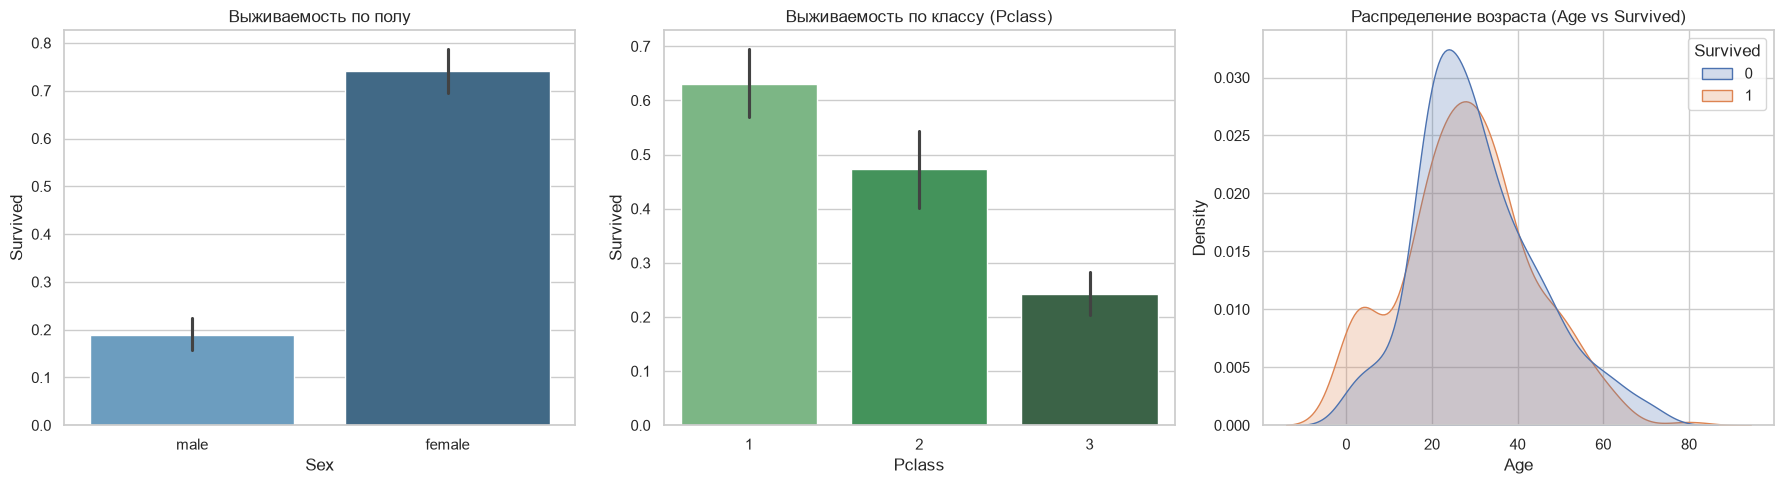

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Выживаемость по полу
sns.barplot(data=train_df, x='Sex', y='Survived', ax=axes[0], palette='Blues_d')
axes[0].set_title('Выживаемость по полу')

# 2. Выживаемость по классу каюты
sns.barplot(data=train_df, x='Pclass', y='Survived', ax=axes[1], palette='Greens_d')
axes[1].set_title('Выживаемость по классу (Pclass)')

# 3. Распределение возраста по статусу выживания
sns.kdeplot(data=train_df, x='Age', hue='Survived', common_norm=False, ax=axes[2], fill=True)
axes[2].set_title('Распределение возраста (Age vs Survived)')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=300)
plt.show()

## 2. Подготовка данных и кодирование признаков

Заполним пропущенные значения, закодируем категориальные переменные и выполним масштабирование числовых признаков.

In [10]:
df = train_df.copy()

# Заполнение пропусков
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Кодирование пола
le_sex = LabelEncoder()
df['Sex_encoded'] = le_sex.fit_transform(df['Sex'])

# One-hot encoding для порта посадки
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

# Отобранные признаки
features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_encoded', 'Embarked_Q', 'Embarked_S']

X = df[features]
y = df['Survived']

# Масштабирование признаков
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=features)

X_scaled.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_encoded,Embarked_Q,Embarked_S
0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,0.737695,-0.307562,0.615838
1,-1.566107,0.663861,0.432793,-0.473674,0.786845,-1.355574,-0.307562,-1.623803
2,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,-1.355574,-0.307562,0.615838
3,-1.566107,0.433312,0.432793,-0.473674,0.420730,-1.355574,-0.307562,0.615838
4,0.827377,0.433312,-0.474545,-0.473674,-0.486337,0.737695,-0.307562,0.615838


## 3. Обучение моделей и оценка качества

Разделим выборку на train/validation и обучим две модели: **Logistic Regression** и **Decision Tree**.

In [11]:
X_train, X_val, y_train, y_val = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)

models = {
    'Logistic Regression': LogisticRegression(max_iter=500, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42)
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    probs = model.predict_proba(X_val)[:, 1]
    
    fitted_models[name] = model
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_val, preds),
        'Precision': precision_score(y_val, preds),
        'Recall': recall_score(y_val, preds),
        'F1': f1_score(y_val, preds),
        'ROC-AUC': roc_auc_score(y_val, probs)
    })

metrics_df = pd.DataFrame(results)
metrics_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.804469,0.793103,0.666667,0.724409,0.843610
1,Decision Tree,0.787709,0.844444,0.550725,0.666667,0.821014


### Визуализация качества моделей

Построим ROC-кривые и матрицы ошибок (Confusion Matrix) для обеих моделей.

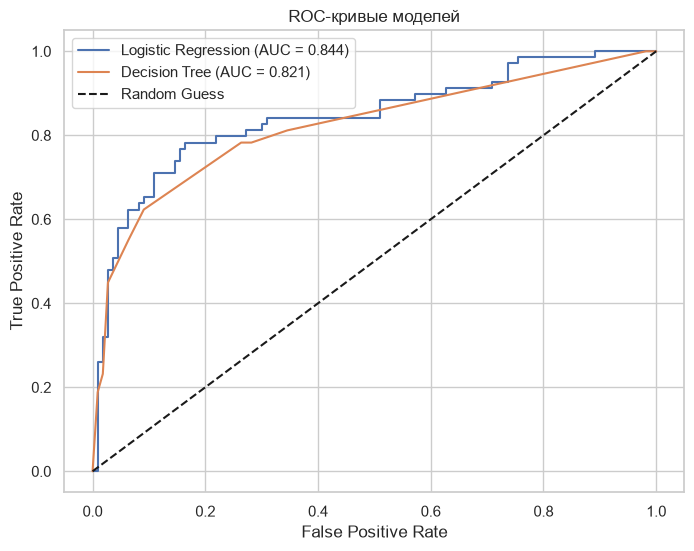

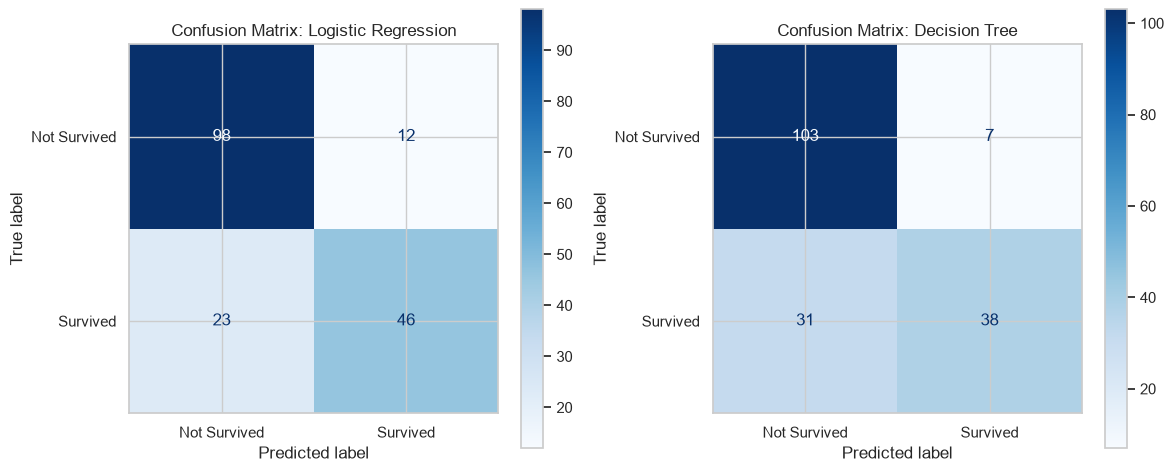

In [12]:
# 1. График ROC-кривых
plt.figure(figsize=(8, 6))

for name, model in fitted_models.items():
    probs = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_val, probs):.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.savefig('examples/roc_curves.png', dpi=300)
plt.show()

# 2. Матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for idx, (name, model) in enumerate(fitted_models.items()):
    preds = model.predict(X_val)
    cm = confusion_matrix(y_val, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Survived', 'Survived'])
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d')
    axes[idx].set_title(f'Confusion Matrix: {name}')

plt.tight_layout()
plt.savefig('examples/confusion_matrices.png', dpi=300)
plt.show()

## 4. Функция предсказания для новых данных

Реализуем функцию, которая принимает параметры нового пассажира и возвращает прогноз (выжил / не выжил) с вероятностью.

In [13]:
def predict_passenger(passenger_data, model, scaler, le_sex, features):
    df_single = pd.DataFrame([passenger_data])
    
    # Кодирование пола
    df_single['Sex_encoded'] = le_sex.transform(df_single['Sex'])
    
    # One-hot encoding для Embarked
    df_single['Embarked_Q'] = 1 if passenger_data.get('Embarked') == 'Q' else 0
    df_single['Embarked_S'] = 1 if passenger_data.get('Embarked') == 'S' else 0
    
    # Отбор признаков
    df_feat = df_single[features]
    
    # Масштабирование
    scaled_data = scaler.transform(df_feat)
    
    pred = model.predict(scaled_data)[0]
    prob = model.predict_proba(scaled_data)[0][1]
    
    return {'Survived': int(pred), 'Probability_Survived': round(float(prob), 4)}

# Пример использования функции
new_passenger = {
    'Pclass': 1,
    'Sex': 'female',
    'Age': 22.0,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 120.0,
    'Embarked': 'S'
}

result = predict_passenger(new_passenger, fitted_models['Logistic Regression'], scaler, le_sex, features)
print("Результат предсказания для нового пассажира:", result)

Результат предсказания для нового пассажира: {'Survived': 1, 'Probability_Survived': 0.9529}


c:\Users\Dinar\Downloads\ml-course-dinar\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
c:\Users\Dinar\Downloads\ml-course-dinar\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## 5. Сохранение моделей и артефактов

Сохраним обученные модели, кодировщики, скалер, список признаков и итоговые метрики на диск[cite: 1].

In [14]:
# Сохраняем модели и трансформаторы
joblib.dump(fitted_models['Logistic Regression'], 'models/lr_model.pkl')
joblib.dump(fitted_models['Decision Tree'], 'models/dt_model.pkl')
joblib.dump(le_sex, 'models/le_sex.pkl')
joblib.dump(scaler, 'models/scaler.pkl')

# Сохраняем список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(features, f, ensure_ascii=False, indent=4)

# Сохраняем метрики
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(results, f, ensure_ascii=False, indent=4)

print("Все модели и артефакты успешно сохранены в папку models/!")

Все модели и артефакты успешно сохранены в папку models/!
